<a href="https://colab.research.google.com/github/luisdavid4564/BioSalud_backend-/blob/main/Copia_de_capitulo3_resultados_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Cargar el dataset (en Colab: sube el .xlsx cuando lo pida)
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
NOMBRE = "Akram et al 2023 Student MH Data UK SciData.xlsx"
RUTA = NOMBRE if os.path.exists(NOMBRE) else "/mnt/user-data/uploads/" + NOMBRE
if not os.path.exists(RUTA):
    from google.colab import files
    files.upload()
    RUTA = NOMBRE
df = pd.read_excel(RUTA)a
os.makedirs("salida", exist_ok=True)
print(df.shape)

(1408, 112)


In [ ]:
# 2. Variables, objetivos y escenarios
DEMO_NUM = ["Age"]
DEMO_CAT = ["Sex", "Gender", "Course_Type", "Ethnicity", "Institution"]
ITEMS_PHQ = [f"PHQ_{i}" for i in range(1, 10)]
ITEMS_GAD = [f"GAD7_{i}" for i in range(1, 8)]

NIV_GAD = ["Mínima", "Leve", "Moderada", "Severa"]
NIV_PHQ = ["Mínima", "Leve", "Moderada", "MS", "Severa"]
OBJETIVOS = {
    "Ansiedad (GAD-7)": dict(y=pd.cut(df["GAD7_Anxiety"], [-1, 4, 9, 14, 21], labels=NIV_GAD).astype(str),
                             niv=NIV_GAD, items=ITEMS_PHQ),
    "Depresión (PHQ-9)": dict(y=pd.cut(df["PHQ9_Depression"], [-1, 4, 9, 14, 19, 27], labels=NIV_PHQ).astype(str),
                              niv=NIV_PHQ, items=ITEMS_GAD),
}
ESCENARIOS = ["A: demográficas", "B: otro cuestionario", "C: otro cuestionario + demográficas"]

def columnas(esc, items):
    if esc.startswith("A"): return DEMO_NUM, DEMO_CAT
    if esc.startswith("B"): return items, []
    return DEMO_NUM + items, DEMO_CAT

X = df[DEMO_NUM + DEMO_CAT + ITEMS_PHQ + ITEMS_GAD].copy()

   Variable objetivo     Nivel    n     %
0   Ansiedad (GAD-7)    Mínima  390  27.7
1   Ansiedad (GAD-7)      Leve  401  28.5
2   Ansiedad (GAD-7)  Moderada  300  21.3
3   Ansiedad (GAD-7)    Severa  317  22.5
4  Depresión (PHQ-9)    Mínima  355  25.2
5  Depresión (PHQ-9)      Leve  390  27.7
6  Depresión (PHQ-9)  Moderada  286  20.3
7  Depresión (PHQ-9)        MS  223  15.8
8  Depresión (PHQ-9)    Severa  154  10.9
                       Característica       Valor
0                    Age (media ± DE)  20.9 ± 4.4
1             Age (valores faltantes)           2
2     Institution (valores faltantes)          15
3     Ítems PHQ-9 (valores faltantes)           0
4     Ítems GAD-7 (valores faltantes)           0
5          Sex (categorías distintas)           3
6       Gender (categorías distintas)           9
7  Course_Type (categorías distintas)           5
8    Ethnicity (categorías distintas)          18
9  Institution (categorías distintas)           6


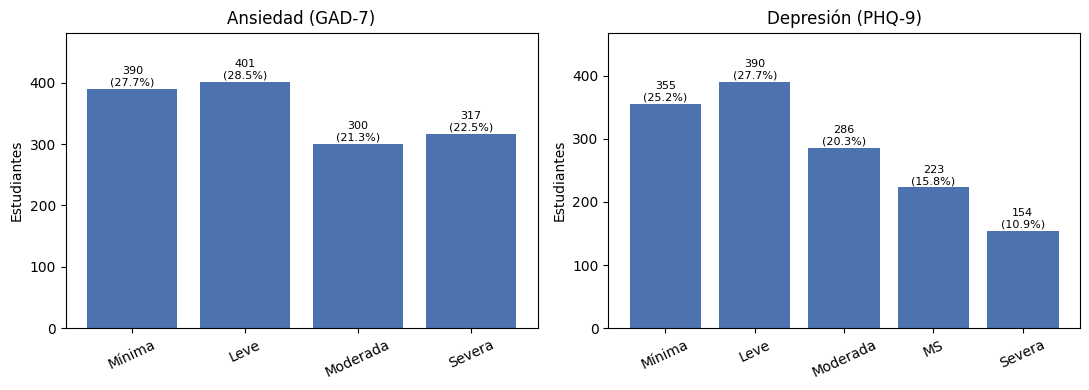

In [ ]:
# 3. TABLA 1 y 2 + FIGURA 1 (descripción del dataset, OE1)
filas = []
for nom, o in OBJETIVOS.items():
    vc = o["y"].value_counts().reindex(o["niv"])
    for n in o["niv"]:
        filas.append([nom, n, int(vc[n]), round(vc[n] / len(o["y"]) * 100, 1)])
tabla1 = pd.DataFrame(filas, columns=["Variable objetivo", "Nivel", "n", "%"])
t2 = [["Age (media ± DE)", f"{df.Age.mean():.1f} ± {df.Age.std():.1f}"],
      ["Age (valores faltantes)", int(df.Age.isna().sum())],
      ["Institution (valores faltantes)", int(df.Institution.isna().sum())],
      ["Ítems PHQ-9 (valores faltantes)", int(df[ITEMS_PHQ].isna().sum().sum())],
      ["Ítems GAD-7 (valores faltantes)", int(df[ITEMS_GAD].isna().sum().sum())]]
for c in DEMO_CAT:
    t2.append([f"{c} (categorías distintas)", int(df[c].nunique())])
tabla2 = pd.DataFrame(t2, columns=["Característica", "Valor"])
print(tabla1); print(tabla2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nom, o) in zip(ax, OBJETIVOS.items()):
    vc = o["y"].value_counts().reindex(o["niv"])
    a.bar(o["niv"], vc.values, color="#4C72B0")
    for i, v in enumerate(vc.values):
        a.text(i, v + 5, f"{v}\n({v/len(o['y'])*100:.1f}%)", ha="center", fontsize=8)
    a.set_title(nom); a.set_ylabel("Estudiantes"); a.tick_params(axis="x", rotation=25); a.set_ylim(0, vc.max() * 1.2)
plt.tight_layout(); plt.savefig("salida/figura1_distribucion.png", dpi=300); plt.show()

In [ ]:
# 4. Pipeline y modelos (OE2, OE3)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

def prepro(num, cat):
    t = []
    if num: t.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num))
    if cat: t.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))]), cat))
    return ColumnTransformer(t)

MODELOS = {
    "Random Forest": (RandomForestClassifier(random_state=42),
        {"m__n_estimators": [100, 300], "m__max_depth": [None, 5, 10], "m__min_samples_leaf": [1, 5]}),
    "KNN": (KNeighborsClassifier(),
        {"m__n_neighbors": [5, 11, 21, 31], "m__weights": ["uniform", "distance"]}),
    "Regresión Logística": (LogisticRegression(max_iter=3000),
        {"m__C": [0.01, 0.1, 1, 10]}),
    "SVM": (SVC(),
        {"m__C": [0.1, 1, 10], "m__kernel": ["rbf", "linear"]}),
}
SEMILLA = 42
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)

In [ ]:
# ============================================================
# 5. ENTRENAMIENTO Y EVALUACIÓN EN PRUEBA (OE3, OE4)
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

res, hip = [], []
est, splits, reportes = {}, {}, {}

for nom, o in OBJETIVOS.items():

    y, niv = o["y"], o["niv"]

    # División entrenamiento / prueba
    Xtr, Xte, ytr, yte = train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=SEMILLA
    )

    splits[nom] = (Xtr, Xte, ytr, yte)

    print(f"\n{'='*70}")
    print(f"OBJETIVO: {nom}")
    print(f"Entrenamiento: {len(Xtr)} | Prueba: {len(Xte)}")
    print(f"{'='*70}")

    # --------------------------------------------------------
    # Línea base
    # --------------------------------------------------------

    base = Pipeline([
        ("p", prepro(DEMO_NUM, DEMO_CAT)),
        ("m", DummyClassifier(strategy="most_frequent"))
    ]).fit(Xtr, ytr)

    p = base.predict(Xte)

    res.append([
        nom,
        "Línea base",
        "Clase mayoritaria",
        accuracy_score(yte, p),
        precision_score(yte, p, average="macro", zero_division=0),
        recall_score(yte, p, average="macro", zero_division=0),
        f1_score(yte, p, average="macro", zero_division=0)
    ])

    # --------------------------------------------------------
    # Entrenamiento de modelos
    # --------------------------------------------------------

    for esc in ESCENARIOS:

        num, cat = columnas(esc, o["items"])

        for nm, (mod, grid) in MODELOS.items():

            pipeline = Pipeline([
                ("p", prepro(num, cat)),
                ("m", mod)
            ])

            gs = GridSearchCV(
                pipeline,
                grid,
                cv=cv,
                scoring="f1_macro",
                n_jobs=-1
            )

            gs.fit(Xtr, ytr)

            # Guardar mejor modelo
            est[(nom, esc, nm)] = gs.best_estimator_

            # Guardar hiperparámetros
            mejores_params = {
                k.replace("m__", ""): v
                for k, v in gs.best_params_.items()
            }

            hip.append([
                nom,
                esc,
                nm,
                str(mejores_params),
                gs.best_score_
            ])

            # Predicción sobre conjunto de prueba
            p = gs.best_estimator_.predict(Xte)

            # Métricas
            res.append([
                nom,
                esc,
                nm,
                accuracy_score(yte, p),
                precision_score(yte, p, average="macro", zero_division=0),
                recall_score(yte, p, average="macro", zero_division=0),
                f1_score(yte, p, average="macro", zero_division=0)
            ])

            # Reporte detallado
            reportes[(nom, esc, nm)] = classification_report(
                yte,
                p,
                labels=niv,
                zero_division=0,
                output_dict=True
            )

        print(f"✓ Completado: {nom} - {esc}")


# ============================================================
# TABLA 1: HIPERPARÁMETROS
# ============================================================

tabla3 = pd.DataFrame(
    hip,
    columns=[
        "Variable objetivo",
        "Escenario",
        "Modelo",
        "Mejores hiperparámetros",
        "F1-macro CV"
    ]
)

tabla3["F1-macro CV"] = tabla3["F1-macro CV"].round(3)


# ============================================================
# TABLA 2: RESULTADOS DE EVALUACIÓN
# ============================================================

tabla4 = pd.DataFrame(
    res,
    columns=[
        "Variable objetivo",
        "Escenario",
        "Modelo",
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1-score macro"
    ]
)

tabla4[
    ["Accuracy", "Precision macro", "Recall macro", "F1-score macro"]
] = tabla4[
    ["Accuracy", "Precision macro", "Recall macro", "F1-score macro"]
].round(3)


# ============================================================
# ORDENAR RESULTADOS
# ============================================================

# Ordenar por variable objetivo, escenario y F1-score
tabla4 = tabla4.sort_values(
    by=["Variable objetivo", "Escenario", "F1-score macro"],
    ascending=[True, True, False]
).reset_index(drop=True)

tabla3 = tabla3.sort_values(
    by=["Variable objetivo", "Escenario", "F1-macro CV"],
    ascending=[True, True, False]
).reset_index(drop=True)


# ============================================================
# MOSTRAR TABLA DE HIPERPARÁMETROS
# ============================================================

print("\n")
print("=" * 100)
print("TABLA DE HIPERPARÁMETROS")
print("=" * 100)

print(
    tabla3.to_string(
        index=False
    )
)


# ============================================================
# MOSTRAR TABLA DE RESULTADOS
# ============================================================

print("\n")
print("=" * 100)
print("TABLA DE RESULTADOS DE EVALUACIÓN")
print("=" * 100)

print(
    tabla4.to_string(
        index=False
    )
)


OBJETIVO: Ansiedad (GAD-7)
Entrenamiento: 1126 | Prueba: 282
✓ Completado: Ansiedad (GAD-7) - A: demográficas
✓ Completado: Ansiedad (GAD-7) - B: otro cuestionario
✓ Completado: Ansiedad (GAD-7) - C: otro cuestionario + demográficas

OBJETIVO: Depresión (PHQ-9)
Entrenamiento: 1126 | Prueba: 282
✓ Completado: Depresión (PHQ-9) - A: demográficas
✓ Completado: Depresión (PHQ-9) - B: otro cuestionario
✓ Completado: Depresión (PHQ-9) - C: otro cuestionario + demográficas


TABLA DE HIPERPARÁMETROS
Variable objetivo                           Escenario              Modelo                                         Mejores hiperparámetros  F1-macro CV
 Ansiedad (GAD-7)                     A: demográficas                 KNN                       {'n_neighbors': 11, 'weights': 'uniform'}        0.278
 Ansiedad (GAD-7)                     A: demográficas       Random Forest {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300}        0.274
 Ansiedad (GAD-7)                     A: demográ

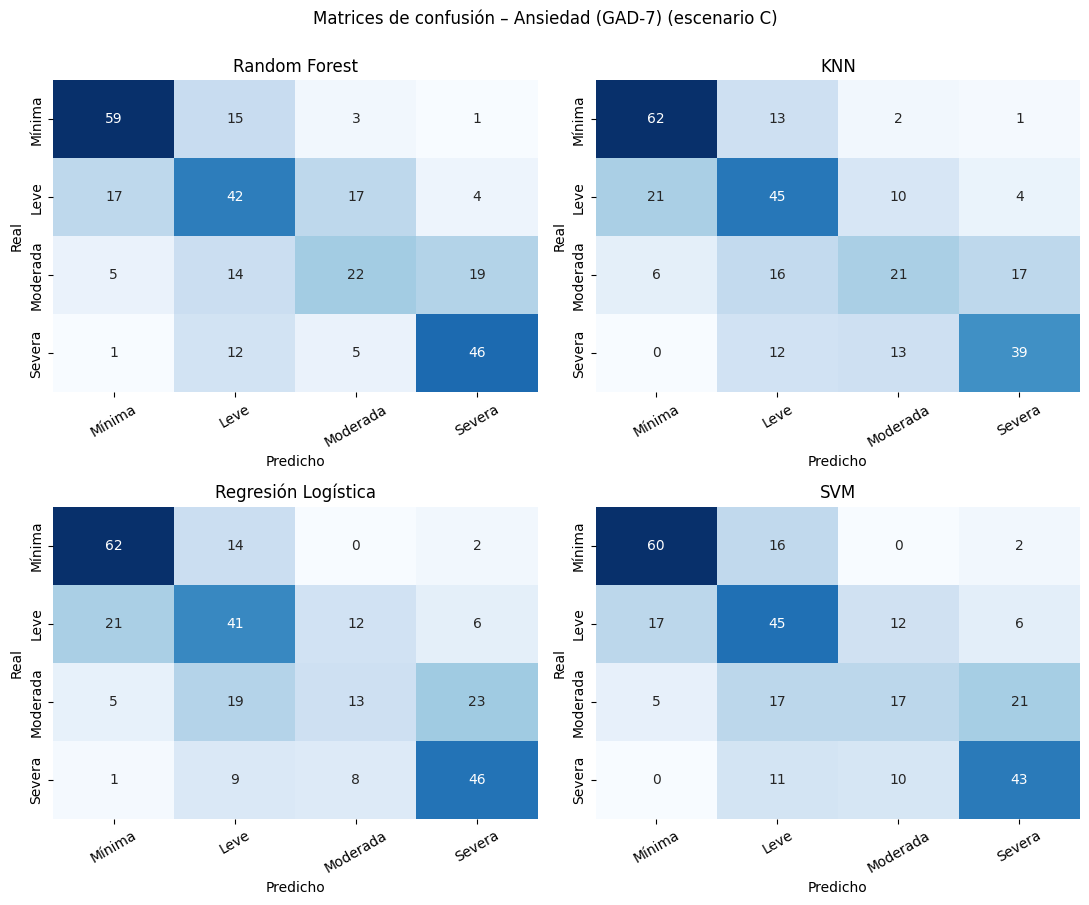

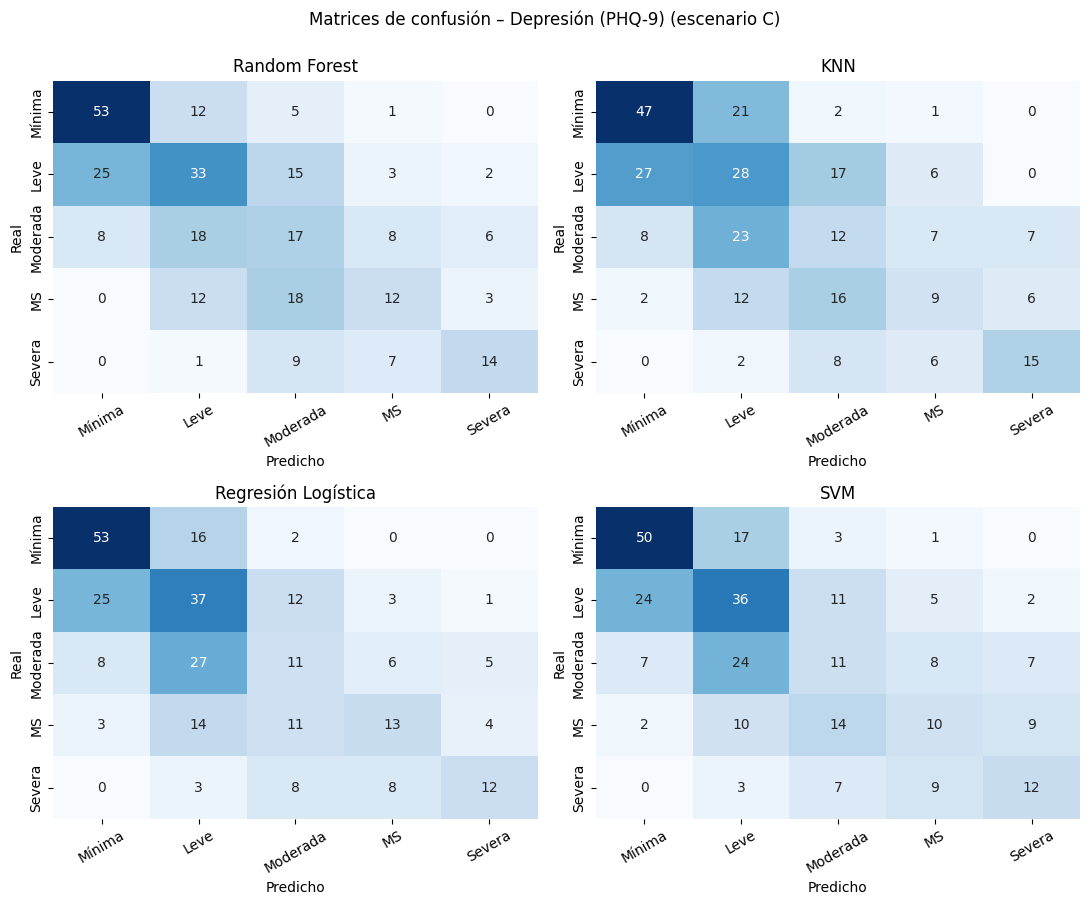

   Variable objetivo Mejor modelo (esc. C)     Nivel  Precision  Recall  F1-score  n (prueba)
0   Ansiedad (GAD-7)         Random Forest    Mínima      0.720   0.756     0.738          78
1   Ansiedad (GAD-7)         Random Forest      Leve      0.506   0.525     0.515          80
2   Ansiedad (GAD-7)         Random Forest  Moderada      0.468   0.367     0.411          60
3   Ansiedad (GAD-7)         Random Forest    Severa      0.657   0.719     0.687          64
4  Depresión (PHQ-9)         Random Forest    Mínima      0.616   0.746     0.675          71
5  Depresión (PHQ-9)         Random Forest      Leve      0.434   0.423     0.429          78
6  Depresión (PHQ-9)         Random Forest  Moderada      0.266   0.298     0.281          57
7  Depresión (PHQ-9)         Random Forest        MS      0.387   0.267     0.316          45
8  Depresión (PHQ-9)         Random Forest    Severa      0.560   0.452     0.500          31


In [ ]:
# 6. TABLA 5 (por clase, mejor modelo del escenario C) + FIGURAS 2 y 3 (matrices de confusión, escenario C)
ESC_P = ESCENARIOS[2]
mejor_C, filas5 = {}, []
for nom, o in OBJETIVOS.items():
    niv = o["niv"]
    sub = tabla4[(tabla4["Variable objetivo"] == nom) & (tabla4["Escenario"] == ESC_P)]
    mejor_C[nom] = sub.sort_values("F1-score macro", ascending=False).iloc[0]["Modelo"]
    for n in niv:
        r = reportes[(nom, ESC_P, mejor_C[nom])][n]
        filas5.append([nom, mejor_C[nom], n, round(r["precision"], 3), round(r["recall"], 3), round(r["f1-score"], 3), int(r["support"])])
    Xtr, Xte, ytr, yte = splits[nom]
    fig, axs = plt.subplots(2, 2, figsize=(11, 9))
    for a, nm in zip(axs.ravel(), MODELOS):
        cm = confusion_matrix(yte, est[(nom, ESC_P, nm)].predict(Xte), labels=niv)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=niv, yticklabels=niv, ax=a)
        a.set_title(nm); a.set_xlabel("Predicho"); a.set_ylabel("Real"); a.tick_params(axis="x", rotation=30)
    fig.suptitle(f"Matrices de confusión – {nom} (escenario C)", y=1.0)
    plt.tight_layout(); plt.savefig(f"salida/figura_matrices_{'ansiedad' if nom.startswith('Ans') else 'depresion'}.png", dpi=300); plt.show()
tabla5 = pd.DataFrame(filas5, columns=["Variable objetivo", "Mejor modelo (esc. C)", "Nivel", "Precision", "Recall", "F1-score", "n (prueba)"])
print(tabla5.to_string())

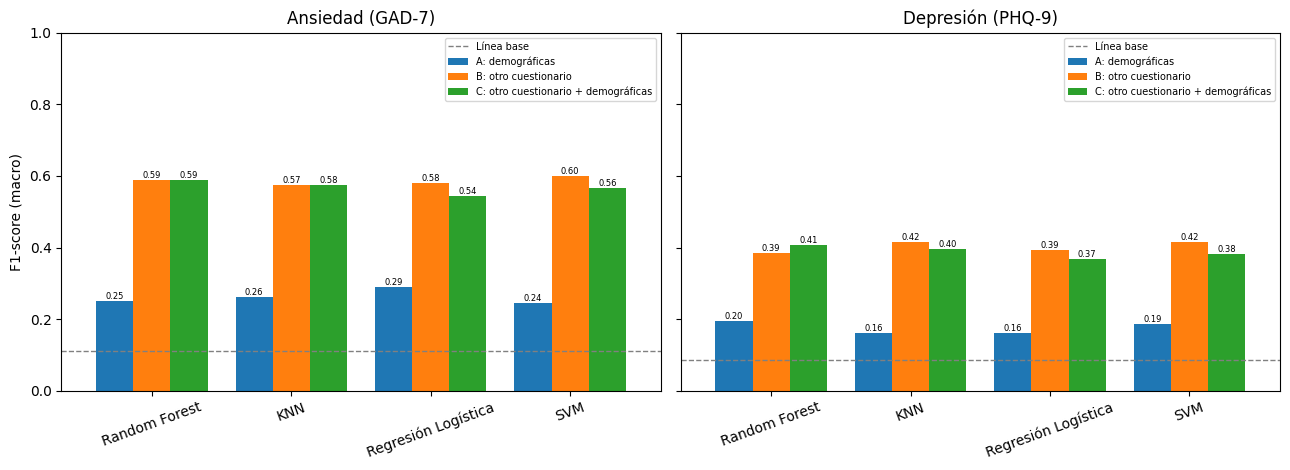

In [ ]:
# 7. FIGURA 4: comparación de modelos y escenarios (OE5)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for a, nom in zip(ax, OBJETIVOS):
    s = tabla4[(tabla4["Variable objetivo"] == nom) & (tabla4["Escenario"] != "—")].pivot(index="Modelo", columns="Escenario", values="F1-score (macro)")[ESCENARIOS]
    s.loc[list(MODELOS)].plot.bar(ax=a, width=0.8); a.set_title(nom); a.set_xlabel(""); a.tick_params(axis="x", rotation=20)
    base = tabla4[(tabla4["Variable objetivo"] == nom) & (tabla4["Escenario"] == "—")]["F1-score (macro)"].iloc[0]
    a.axhline(base, color="gray", ls="--", lw=1, label="Línea base"); a.set_ylim(0, 1); a.set_ylabel("F1-score (macro)")
    for c in a.containers: a.bar_label(c, fmt="%.2f", fontsize=6)
    a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("salida/figura4_comparacion.png", dpi=300); plt.show()

In [ ]:
# 8. Comparación estadística (HE5): Friedman entre algoritmos en escenario C, y Wilcoxon B vs C (aporte de demográficas)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from scipy.stats import friedmanchisquare, wilcoxon
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
f6, f7 = [], []
for nom in OBJETIVOS:
    Xtr, Xte, ytr, yte = splits[nom]
    sc = {m: cross_val_score(est[(nom, ESC_P, m)], Xtr, ytr, cv=rcv, scoring="f1_macro", n_jobs=-1) for m in MODELOS}
    stat, p = friedmanchisquare(*sc.values())
    for m, v in sc.items():
        f6.append([nom, m, round(v.mean(), 3), round(v.std(), 3), round(stat, 3), round(p, 4)])
    m = mejor_C[nom]
    sB = cross_val_score(est[(nom, ESCENARIOS[1], m)], Xtr, ytr, cv=rcv, scoring="f1_macro", n_jobs=-1)
    sC = sc[m]
    f7.append([nom, m, round(sB.mean(), 3), round(sC.mean(), 3), round(sC.mean() - sB.mean(), 3), round(wilcoxon(sB, sC).pvalue, 4)])
tabla6 = pd.DataFrame(f6, columns=["Variable objetivo", "Modelo", "F1-macro media (CV)", "DE", "Chi² Friedman", "p"])
tabla7 = pd.DataFrame(f7, columns=["Variable objetivo", "Modelo", "F1 esc. B", "F1 esc. C", "Diferencia (C-B)", "p (Wilcoxon)"])
print(tabla6.to_string()); print(tabla7.to_string())

   Variable objetivo               Modelo  F1-macro media (CV)     DE  Chi² Friedman       p
0   Ansiedad (GAD-7)        Random Forest                0.550  0.029           8.20  0.0421
1   Ansiedad (GAD-7)                  KNN                0.535  0.033           8.20  0.0421
2   Ansiedad (GAD-7)  Regresión Logística                0.533  0.023           8.20  0.0421
3   Ansiedad (GAD-7)                  SVM                0.551  0.022           8.20  0.0421
4  Depresión (PHQ-9)        Random Forest                0.477  0.034           5.96  0.1136
5  Depresión (PHQ-9)                  KNN                0.469  0.040           5.96  0.1136
6  Depresión (PHQ-9)  Regresión Logística                0.474  0.036           5.96  0.1136
7  Depresión (PHQ-9)                  SVM                0.485  0.039           5.96  0.1136
   Variable objetivo         Modelo  F1 esc. B  F1 esc. C  Diferencia (C-B)  p (Wilcoxon)
0   Ansiedad (GAD-7)  Random Forest      0.557      0.550            -0.0

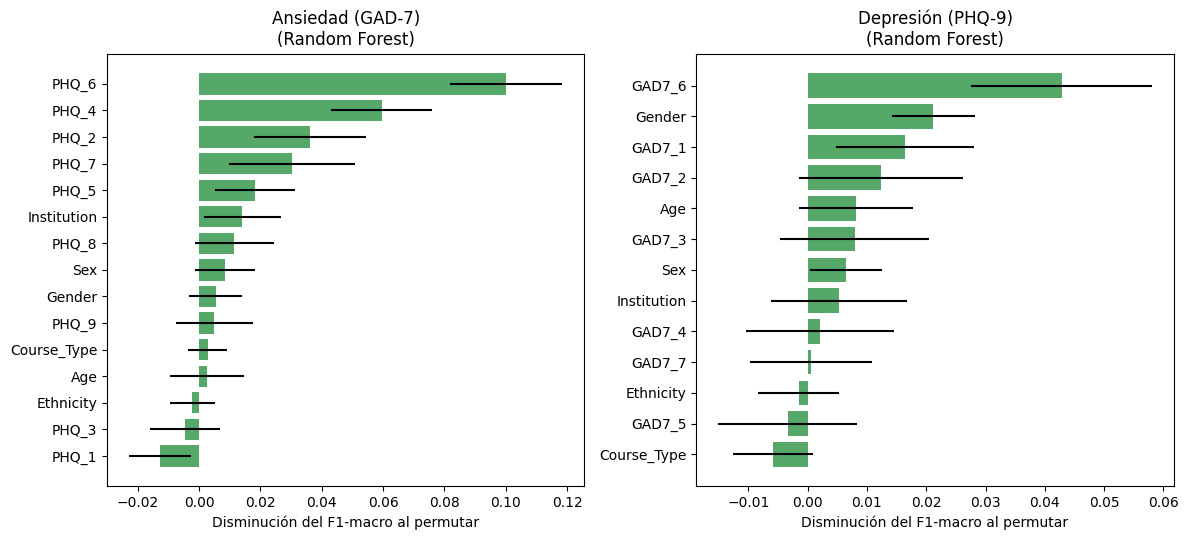

In [ ]:
# 9. FIGURA 5: importancia por permutación (mejor modelo, escenario C)
from sklearn.inspection import permutation_importance
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, nom in zip(ax, OBJETIVOS):
    num, cat = columnas(ESC_P, OBJETIVOS[nom]["items"]); cols = num + cat
    Xtr, Xte, ytr, yte = splits[nom]
    pi = permutation_importance(est[(nom, ESC_P, mejor_C[nom])], Xte[cols], yte, scoring="f1_macro", n_repeats=30, random_state=SEMILLA)
    s = pd.Series(pi.importances_mean, index=cols).sort_values(); sd = pd.Series(pi.importances_std, index=cols)[s.index]
    a.barh(s.index, s.values, xerr=sd.values, color="#55A868")
    a.set_title(f"{nom}\n({mejor_C[nom]})"); a.set_xlabel("Disminución del F1-macro al permutar")
plt.tight_layout(); plt.savefig("salida/figura5_importancia.png", dpi=300); plt.show()

In [ ]:
# 10. Exportar todas las tablas a Excel
with pd.ExcelWriter("salida/tablas_resultados.xlsx") as w:
    for n, t in [("T1_distribucion", tabla1), ("T2_predictores", tabla2), ("T3_hiperparametros", tabla3),
                 ("T4_comparacion", tabla4), ("T5_por_clase", tabla5), ("T6_friedman", tabla6), ("T7_B_vs_C", tabla7)]:
        t.to_excel(w, sheet_name=n, index=False)
print(os.listdir("salida"))

['figura4_comparacion.png', 'figura1_distribucion.png', 'figura_matrices_ansiedad.png', 'tablas_resultados.xlsx', 'figura_matrices_depresion.png', 'figura5_importancia.png']
